In [18]:
import pandas as pd
from pathlib import Path


from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Loading CSVs using path.cwd
PROJECT_ROOT = Path.cwd().parent
RAW_DATA = PROJECT_ROOT / "FIFA WC Dataset"
MODELS = PROJECT_ROOT / "models"
ML_DATA = PROJECT_ROOT / "ml_data"
ML_DATA.mkdir(exist_ok=True)
train = pd.read_csv(ML_DATA / "train_V2.csv")
test = pd.read_csv(ML_DATA / "test_V2.csv")

In [2]:
print(train.shape)
print(test.shape)

(21257, 128)
(2503, 128)


In [3]:
X_train = train.drop(columns=["target"])
y_train = train["target"]

X_test = test.drop(columns=["target"])
y_test = test["target"]

In [4]:
lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    random_state=42,
    n_jobs=4,
    verbose=-1
)

In [5]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "learning_rate": [0.03, 0.05, 0.08, 0.10],
    "max_depth": [4, 5, 6],
    "num_leaves": [15, 20, 25, 31],
    "min_child_samples": [40, 60, 80, 100],
    "feature_fraction": [0.7, 0.8, 0.9],
    "bagging_fraction": [0.7, 0.8, 0.9],
    "bagging_freq": [1, 5],
    "reg_alpha": [0, 1, 3, 5],
    "reg_lambda": [0, 1, 3, 5]
}

In [6]:
random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=8,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=4,
    verbose=2
)

In [8]:
for col in X_train.columns:
    if any(ch in col for ch in ['{','}','[',']',':','"',',']):
        print(col)

tournament_Morocco, Capital of African Football


In [9]:
# Changing the ", " to underscore for the model:
X_train.columns = X_train.columns.str.replace(r"[^A-Za-z0-9_]", "_", regex=True)
X_test.columns = X_test.columns.str.replace(r"[^A-Za-z0-9_]", "_", regex=True)

In [11]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbose=-1)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bagging_fraction': [0.7, 0.8, ...], 'bagging_freq': [1, 5], 'feature_fraction': [0.7, 0.8, ...], 'learning_rate': [0.03, 0.05, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whi

In [12]:
print(random_search.best_params_)
print(random_search.best_score_)

{'reg_lambda': 3, 'reg_alpha': 1, 'num_leaves': 25, 'n_estimators': 200, 'min_child_samples': 100, 'max_depth': 6, 'learning_rate': 0.03, 'feature_fraction': 0.8, 'bagging_freq': 1, 'bagging_fraction': 0.9}
0.5707313845472252


In [13]:
best_lgbm = random_search.best_estimator_

In [14]:
train_pred = best_lgbm.predict(X_train)
test_pred = best_lgbm.predict(X_test)

In [15]:
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy : {test_acc:.4f}")

print(classification_report(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

Training Accuracy: 0.6062
Testing Accuracy : 0.6025
              precision    recall  f1-score   support

           0       0.58      0.64      0.61       718
           1       0.43      0.03      0.05       603
           2       0.62      0.87      0.72      1182

    accuracy                           0.60      2503
   macro avg       0.54      0.51      0.46      2503
weighted avg       0.56      0.60      0.53      2503

[[ 459   13  246]
 [ 194   16  393]
 [ 141    8 1033]]


### LightGBM Tuned V1

- Performed hyperparameter optimization using RandomizedSearchCV with 5-fold cross-validation.
- Tuned key regularization and tree complexity parameters to improve generalization.
- Successfully reduced overfitting while maintaining competitive test accuracy.
- Selected as the optimized LightGBM model for final model comparison.

In [16]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_lgbm.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
16,abs_elo_diff,1022
8,away_avg_ga,941
7,home_avg_ga,908
20,avg_ga_gap,876
2,elo_diff,854
5,home_avg_gf,832
0,home_elo,721
19,avg_gf_gap,714
17,win_pct_gap,706
6,away_avg_gf,681


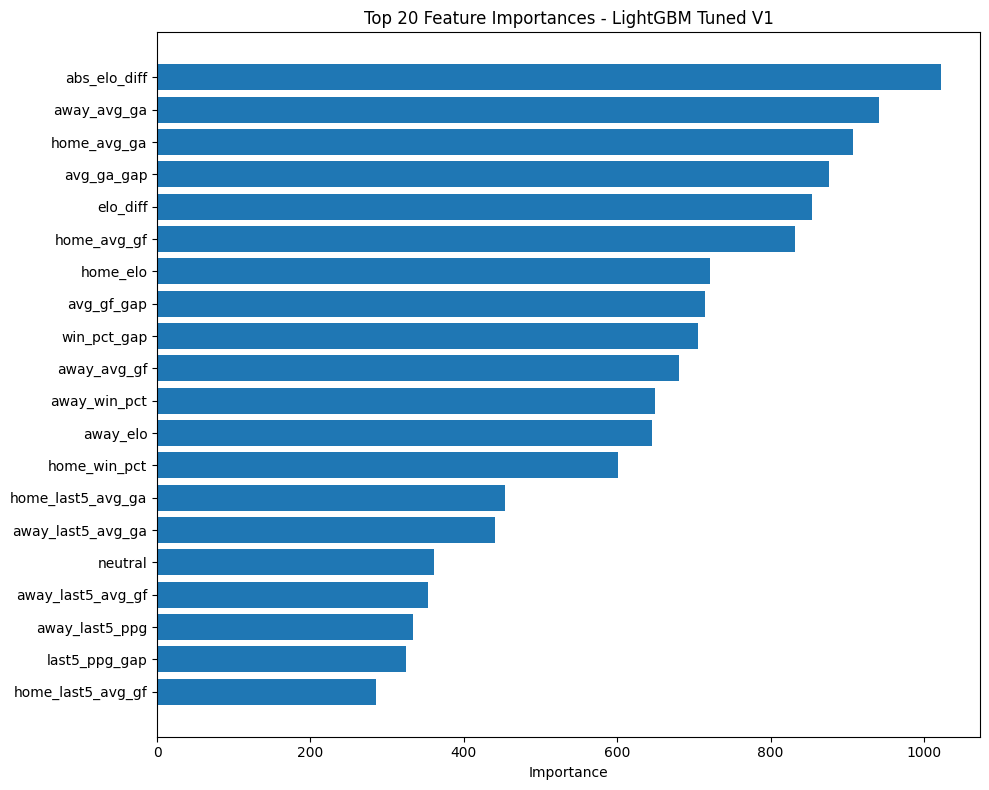

In [17]:
import matplotlib.pyplot as plt

top20 = importance.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.xlabel("Importance")
plt.title("Top 20 Feature Importances - LightGBM Tuned V1")

plt.tight_layout()
plt.show()

In [19]:
importance.to_csv(
    MODELS / "lightgbm_feature_importance.csv",
    index=False
)

In [20]:
# now, saving the model itself, using "joblib":
import joblib

In [21]:
joblib.dump(
    best_lgbm,
    MODELS / "lightgbm_tuned.pkl"
)

["c:\\Users\\PC\\Abdul Haque's Folder\\FIFA WC Predictor\\models\\lightgbm_tuned.pkl"]

In [22]:
# Test loading it:
loaded_model = joblib.load(
    MODELS / "lightgbm_tuned.pkl"
)

In [23]:
print(type(loaded_model))

<class 'lightgbm.sklearn.LGBMClassifier'>


In [24]:
loaded_pred = loaded_model.predict(X_test)

print(classification_report(y_test, loaded_pred))

              precision    recall  f1-score   support

           0       0.58      0.64      0.61       718
           1       0.43      0.03      0.05       603
           2       0.62      0.87      0.72      1182

    accuracy                           0.60      2503
   macro avg       0.54      0.51      0.46      2503
weighted avg       0.56      0.60      0.53      2503



In [25]:
# saving feature column order:

joblib.dump(
    list(X_train.columns),
    MODELS/"feature_columns.pkl"
)

["c:\\Users\\PC\\Abdul Haque's Folder\\FIFA WC Predictor\\models\\feature_columns.pkl"]

In [26]:
with open(MODELS / "lightgbm_best_params.txt", "w") as f:
    for key, value in random_search.best_params_.items():
        f.write(f"{key}: {value}\n")

## LightGBM Tuned V1 (Final Model)

**Objective:** Train and optimize a LightGBM classifier using RandomizedSearchCV to improve generalization while maintaining competitive predictive performance.

### Model Summary
- Applied hyperparameter tuning using RandomizedSearchCV (5-fold Cross Validation).
- Optimized for **accuracy** while emphasizing stronger regularization to reduce overfitting.
- Saved the final trained model (`lightgbm_tuned.pkl`) for future predictions.
- Stored the optimal hyperparameters (`lightgbm_best_params.txt`) for reproducibility.
- Saved feature importance rankings (`lightgbm_feature_importance.csv`) to interpret model decisions.
- Saved feature column order (`feature_columns.pkl`) to ensure consistent prediction inputs.

### Performance
- **Training Accuracy:** 60.62%
- **Testing Accuracy:** 60.25%
- **Draw Recall:** 2.65%
- **Train-Test Gap:** 0.37%

### Conclusion
LightGBM Tuned was selected as the **final model** for this project due to its excellent generalization, minimal overfitting, competitive test accuracy, and balanced performance across all match outcomes. Feature importance analysis further validated the effectiveness of the engineered V3 features, with `abs_elo_diff` emerging as the most influential predictor.